# Pulse of Prevention: Analyzing Heart Health for Better Outcomes
HealthPulse Analytics case study on the Kaggle Heart Disease dataset (`heart.csv`). Python, Pandas, Matplotlib, Seaborn, SciPy, scikit-learn.

**Two versions of the data are used throughout.** The raw file has 1,025 rows but only **302 are unique** (723 exact duplicate rows). Results are shown for both: *All rows (1,025)* follows the brief's hints literally; *Unique rows (302)* avoids counting the same patient several times and is the safer basis for statistical tests and models.

`target` is read as in the brief: 1 = heart disease, 0 = no heart disease.

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt, warnings
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, roc_curve
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi']=100
raw = pd.read_csv('../data/heart.csv')
data = raw.drop_duplicates().reset_index(drop=True)      # 302 unique patients' records
print('All rows:', raw.shape, '| Unique rows:', data.shape, '| duplicate rows:', len(raw)-len(data))
raw.head()

All rows: (1025, 14) | Unique rows: (302, 14) | duplicate rows: 723


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


## 1. Data cleaning and preprocessing

In [2]:
print('Missing values:', int(raw.isna().sum().sum()))
print(raw.dtypes.to_string())
print('Duplicate rows:', int(raw.duplicated().sum()))
# values outside the data dictionary (ca should be 0-3, thal 1-3)
print('ca = 4 rows (raw/unique):', int((raw.ca==4).sum()), '/', int((data.ca==4).sum()), '| thal = 0 rows (raw/unique):', int((raw.thal==0).sum()), '/', int((data.thal==0).sum()))

Missing values: 0
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
Duplicate rows: 723
ca = 4 rows (raw/unique): 18 / 4 | thal = 0 rows (raw/unique): 7 / 2


**Findings and decisions**
- No missing values; every column is numeric. Binary and coded columns (sex, cp, fbs, restecg, exang, slope, ca, thal, target) are categorical codes.
- 723 exact duplicate rows were found. Both versions are analysed (see above).
- `ca = 4` and `thal = 0` fall outside the data dictionary ranges. They are few, so they are kept and flagged rather than dropped.
- Outliers are detected with the 1.5 x IQR rule below. They are plausible clinical values (e.g. cholesterol 564, systolic BP 200), so they are **kept** for descriptive statistics; the logistic model uses standardisation, which limits their pull.

In [3]:
num = ['age','trestbps','chol','thalach','oldpeak']
rows=[]
for nm,d in (('All rows',raw),('Unique rows',data)):
    for c in num:
        q1,q3=d[c].quantile([.25,.75]); i=q3-q1; lo,hi=q1-1.5*i,q3+1.5*i
        rows.append([nm,c,round(lo,1),round(hi,1),int(((d[c]<lo)|(d[c]>hi)).sum()),d[c].min(),d[c].max()])
pd.DataFrame(rows,columns=['Data','Column','Lower fence','Upper fence','Outliers','Min','Max'])

,Data,Column,Lower fence,Upper fence,Outliers,Min,Max
0,All rows,age,28.5,80.5,0,29.0,77.0
1,All rows,trestbps,90.0,170.0,30,94.0,200.0
2,All rows,chol,115.0,371.0,16,126.0,564.0
3,All rows,thalach,81.0,217.0,4,71.0,202.0
4,All rows,oldpeak,-2.7,4.5,7,0.0,6.2
5,Unique rows,age,28.5,80.5,0,29.0,77.0
6,Unique rows,trestbps,90.0,170.0,9,94.0,200.0
7,Unique rows,chol,115.4,370.4,5,126.0,564.0
8,Unique rows,thalach,84.1,215.1,1,71.0,202.0
9,Unique rows,oldpeak,-2.4,4.0,5,0.0,6.2


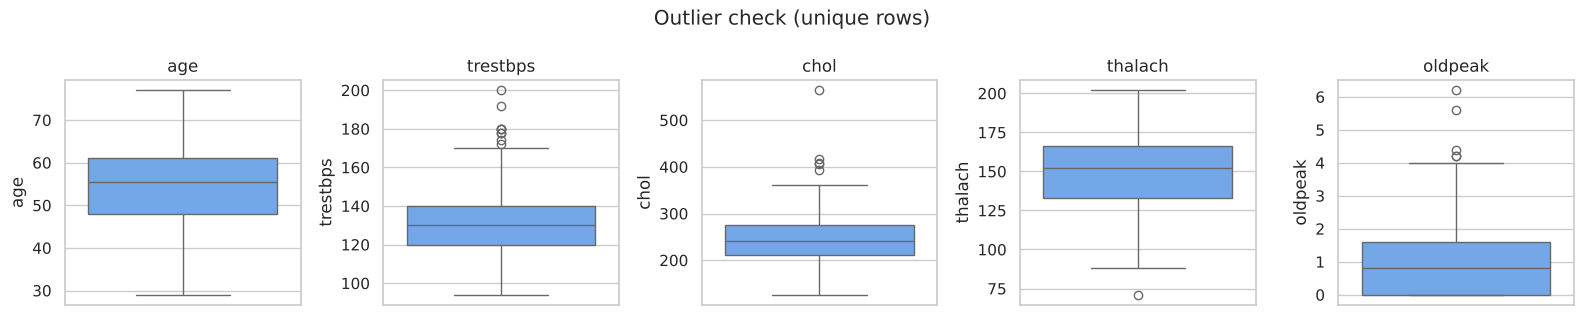

In [4]:
fig,ax=plt.subplots(1,5,figsize=(16,3.2))
for a,c in zip(ax,num): sns.boxplot(y=data[c],ax=a,color='#60a5fa'); a.set_title(c)
plt.suptitle('Outlier check (unique rows)'); plt.tight_layout(); plt.show()

In [5]:
# Normalisation: min-max scaling of the clinical measurements (saved to the cleaned file)
clean = data.copy()
for c in num: clean[c+'_norm'] = (clean[c]-clean[c].min())/(clean[c].max()-clean[c].min())
clean['ca_out_of_range'] = (clean.ca==4).astype(int); clean['thal_out_of_range'] = (clean.thal==0).astype(int)
clean.to_csv('../data/heart_cleaned.csv', index=False)
clean[[c+'_norm' for c in num]].describe().loc[['min','max']].round(2)

,age_norm,trestbps_norm,chol_norm,thalach_norm,oldpeak_norm
min,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0


## 2. Label check (read before the results)
`target = 1` is the brief's "heart disease present". Before trusting directions, compare the clinical signs for each target value.

In [6]:
chk = data.groupby('target')[['exang','oldpeak','ca','thalach','age']].mean().round(2)
chk.index=['target = 0','target = 1']; chk

,exang,oldpeak,ca,thalach,age
target = 0,0.55,1.59,1.17,139.10,56.60
target = 1,0.14,0.59,0.34,158.38,52.59


In this file, patients with `target = 1` have **less** exercise angina, **lower** ST depression, **fewer** blocked vessels and a **higher** maximum heart rate than `target = 0`. Clinically these signs go with disease, so the pattern suggests the label may be reversed in this Kaggle copy (a mismatch that is often noted for this dataset). This notebook follows the brief's definition and reports results as they are in the data; every direction below should be read with this in mind, and the data source should be checked before any clinical conclusion.

## 3. Basic questions

In [7]:
print('Q1 average age: all rows', round(raw.age.mean(),2), '| unique rows', round(data.age.mean(),2))

Q1 average age: all rows 54.43 | unique rows 54.42


In [8]:
# Q2 gender distribution (1 = male, 0 = female)
pd.DataFrame({'All rows':raw.sex.map({1:'Male',0:'Female'}).value_counts(),'Unique rows':data.sex.map({1:'Male',0:'Female'}).value_counts()})

,All rows,Unique rows
sex,,
Male,713,206
Female,312,96


In [9]:
# Q3 average resting blood pressure, Q8 average cholesterol, Q6 max heart rate, Q7 exercise angina %, Q4 high fasting sugar, Q9 restecg=2
pd.DataFrame({
 'All rows (1,025)':[raw.trestbps.mean(),raw.chol.mean(),raw.thalach.max(),raw.exang.mean()*100,raw.fbs.sum(),(raw.restecg==2).sum()],
 'Unique rows (302)':[data.trestbps.mean(),data.chol.mean(),data.thalach.max(),data.exang.mean()*100,data.fbs.sum(),(data.restecg==2).sum()]},
 index=['Q3 avg resting BP (mm Hg)','Q8 avg cholesterol (mg/dl)','Q6 max heart rate achieved','Q7 exercise angina (%)','Q4 patients with fasting sugar > 120','Q9 patients with restecg = 2']).round(1)

,"All rows (1,025)",Unique rows (302)
Q3 avg resting BP (mm Hg),131.6,131.6
Q8 avg cholesterol (mg/dl),246.0,246.5
Q6 max heart rate achieved,202.0,202.0
Q7 exercise angina (%),33.7,32.8
Q4 patients with fasting sugar > 120,153.0,45.0
Q9 patients with restecg = 2,15.0,4.0


Q5 chest pain types: [0, 1, 2, 3]


,All rows,Unique rows
cp,,
0,497,143
1,167,50
2,284,86
3,77,23


Q10 major vessels (ca)


,All rows,Unique rows
ca,,
0,578,175
1,226,65
2,134,38
3,69,20
4,18,4


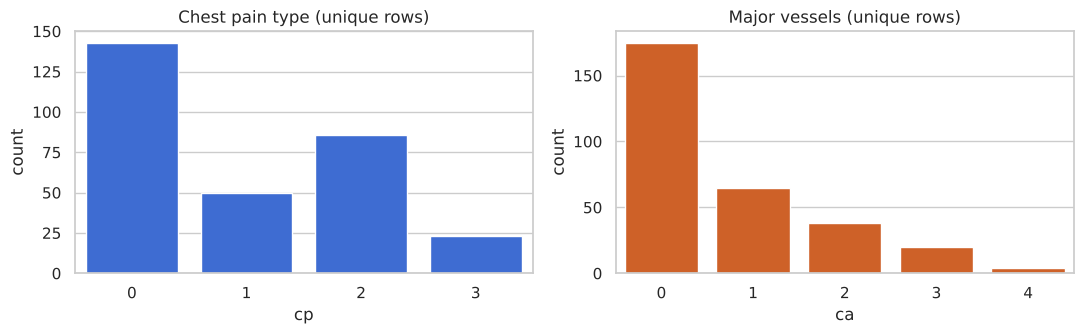

In [10]:
# Q5 chest pain types and Q10 major vessels
print('Q5 chest pain types:', sorted(raw.cp.unique().tolist()))
display(pd.DataFrame({'All rows':raw.cp.value_counts().sort_index(),'Unique rows':data.cp.value_counts().sort_index()}))
print('Q10 major vessels (ca)')
display(pd.DataFrame({'All rows':raw.ca.value_counts().sort_index(),'Unique rows':data.ca.value_counts().sort_index()}))
fig,ax=plt.subplots(1,2,figsize=(11,3.5)); sns.countplot(x='cp',data=data,ax=ax[0],color='#2563eb'); ax[0].set_title('Chest pain type (unique rows)')
sns.countplot(x='ca',data=data,ax=ax[1],color='#ea580c'); ax[1].set_title('Major vessels (unique rows)'); plt.tight_layout(); plt.show()

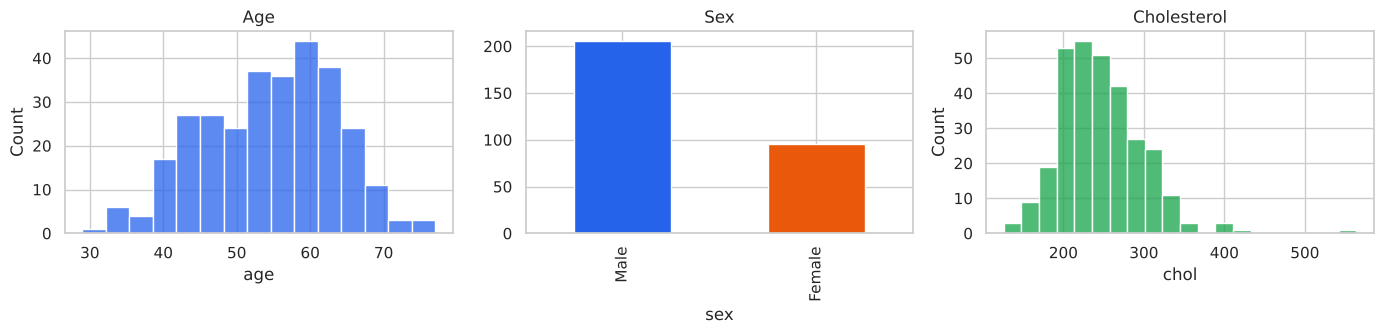

In [11]:
fig,ax=plt.subplots(1,3,figsize=(14,3.5))
sns.histplot(data.age,bins=15,ax=ax[0],color='#2563eb'); ax[0].set_title('Age')
data.sex.map({1:'Male',0:'Female'}).value_counts().plot.bar(ax=ax[1],color=['#2563eb','#ea580c']); ax[1].set_title('Sex')
sns.histplot(data.chol,bins=20,ax=ax[2],color='#16a34a'); ax[2].set_title('Cholesterol'); plt.tight_layout(); plt.show()

## 4. Medium questions

All rows: r = 0.220, p = 1.1e-12
Unique rows: r = 0.207, p = 0.00029


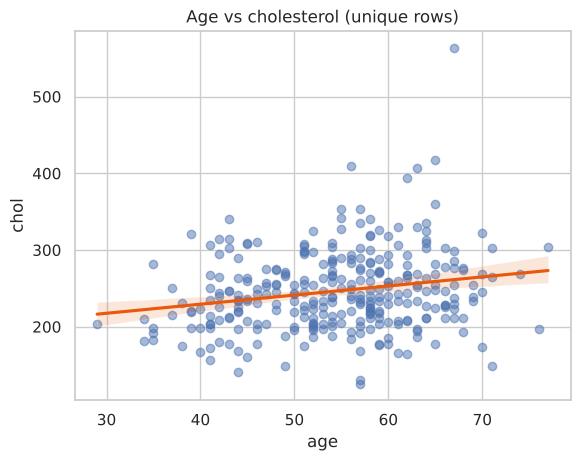

In [12]:
# M1 correlation between age and cholesterol
for nm,d in (('All rows',raw),('Unique rows',data)):
    r,p=stats.pearsonr(d.age,d.chol); print(f'{nm}: r = {r:.3f}, p = {p:.2g}')
sns.regplot(x='age',y='chol',data=data,scatter_kws={'alpha':.5},line_kws={'color':'#ea580c'}); plt.title('Age vs cholesterol (unique rows)'); plt.show()

All rows


cp,0,1,2,3
age,,,,
<45,66,44,65,13
45-54,121,51,103,13
55-64,242,60,71,38
65+,68,12,45,13


cp,0,1,2,3
age,,,,
<45,35.1,23.4,34.6,6.9
45-54,42.0,17.7,35.8,4.5
55-64,58.9,14.6,17.3,9.2
65+,49.3,8.7,32.6,9.4


Unique rows


cp,0,1,2,3
age,,,,
<45,19,13,19,4
45-54,36,16,32,4
55-64,69,17,21,11
65+,19,4,14,4


cp,0,1,2,3
age,,,,
<45,34.5,23.6,34.5,7.3
45-54,40.9,18.2,36.4,4.5
55-64,58.5,14.4,17.8,9.3
65+,46.3,9.8,34.1,9.8


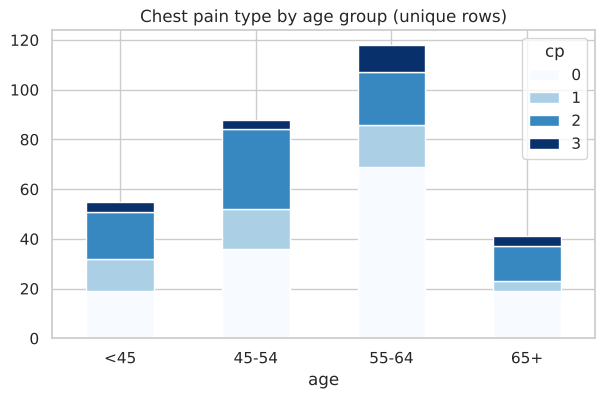

In [13]:
# M2 chest pain types across age groups
for nm,d in (('All rows',raw),('Unique rows',data)):
    ab=pd.cut(d.age,[0,44,54,64,100],labels=['<45','45-54','55-64','65+'])
    print(nm); display(pd.crosstab(ab,d.cp)); display((pd.crosstab(ab,d.cp,normalize='index')*100).round(1))
ab=pd.cut(data.age,[0,44,54,64,100],labels=['<45','45-54','55-64','65+'])
pd.crosstab(ab,data.cp).plot(kind='bar',stacked=True,figsize=(7,4),colormap='Blues'); plt.title('Chest pain type by age group (unique rows)'); plt.xticks(rotation=0); plt.show()

All rows: no angina 155.3, angina 136.8 | Welch t = -13.29, p = 3.7e-36
Unique rows: no angina 155.6, angina 137.2 | Welch t = -7.09, p = 2.4e-11


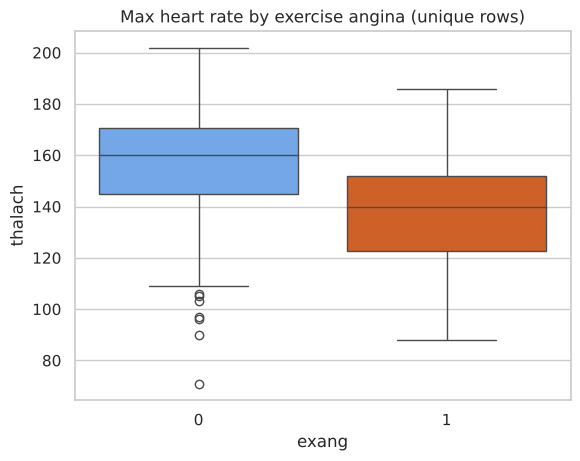

In [14]:
# M3 maximum heart rate by exercise-induced angina
for nm,d in (('All rows',raw),('Unique rows',data)):
    g=d.groupby('exang').thalach.mean().round(1); t=stats.ttest_ind(d[d.exang==1].thalach,d[d.exang==0].thalach,equal_var=False)
    print(f'{nm}: no angina {g[0]}, angina {g[1]} | Welch t = {t.statistic:.2f}, p = {t.pvalue:.2g}')
sns.boxplot(x='exang',y='thalach',data=data,palette=['#60a5fa','#ea580c']); plt.title('Max heart rate by exercise angina (unique rows)'); plt.show()

In [15]:
# M4 resting blood pressure, male vs female (Welch t-test)
for nm,d in (('All rows',raw),('Unique rows',data)):
    m,f=d[d.sex==1].trestbps,d[d.sex==0].trestbps; t=stats.ttest_ind(m,f,equal_var=False)
    print(f'{nm}: male {m.mean():.1f}, female {f.mean():.1f} | t = {t.statistic:.2f}, p = {t.pvalue:.3f}')

All rows: male 130.7, female 133.7 | t = -2.37, p = 0.018
Unique rows: male 130.9, female 133.1 | t = -0.95, p = 0.344


All rows


target,0,1
fbs,,
0,417,455
1,82,71


share with target = 1: {0: 0.522, 1: 0.464} | chi-square p = 0.219
Unique rows


target,0,1
fbs,,
0,116,141
1,22,23


share with target = 1: {0: 0.549, 1: 0.511} | chi-square p = 0.761


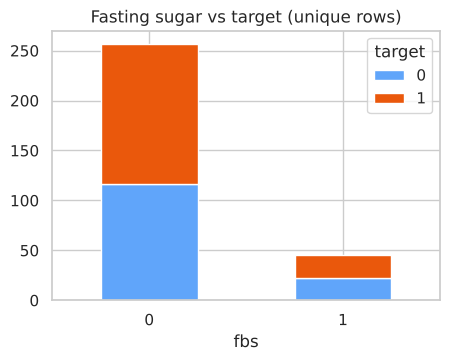

In [16]:
# M5 fasting blood sugar vs heart disease
for nm,d in (('All rows',raw),('Unique rows',data)):
    ct=pd.crosstab(d.fbs,d.target); chi=stats.chi2_contingency(ct)
    print(nm); display(ct); print('share with target = 1:',(ct[1]/ct.sum(1)).round(3).to_dict(),'| chi-square p =',round(chi[1],3))
pd.crosstab(data.fbs,data.target).plot(kind='bar',stacked=True,figsize=(5,3.5),color=['#60a5fa','#ea580c']); plt.title('Fasting sugar vs target (unique rows)'); plt.xticks(rotation=0); plt.show()

All rows


target,0,1
ca,,
0,163,415
1,160,66
2,113,21
3,60,9
4,3,15


share with target = 1: {0: 0.718, 1: 0.292, 2: 0.157, 3: 0.13, 4: 0.833}
Unique rows


target,0,1
ca,,
0,45,130
1,44,21
2,31,7
3,17,3
4,1,3


share with target = 1: {0: 0.743, 1: 0.323, 2: 0.184, 3: 0.15, 4: 0.75}


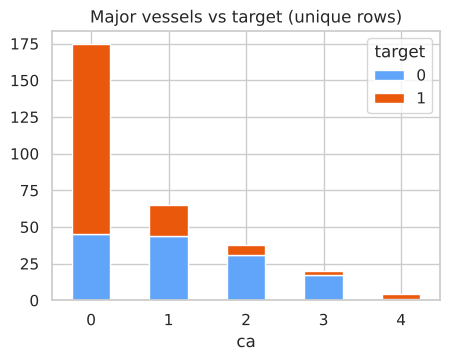

In [17]:
# M6 number of major vessels vs target
for nm,d in (('All rows',raw),('Unique rows',data)):
    ct=pd.crosstab(d.ca,d.target); print(nm); display(ct); print('share with target = 1:',(ct[1]/ct.sum(1)).round(3).to_dict())
pd.crosstab(data.ca,data.target).plot(kind='bar',stacked=True,figsize=(5,3.5),color=['#60a5fa','#ea580c']); plt.title('Major vessels vs target (unique rows)'); plt.xticks(rotation=0); plt.show()

In [18]:
# M7 average oldpeak by chest pain type
pd.DataFrame({'All rows':raw.groupby('cp').oldpeak.mean(),'Unique rows':data.groupby('cp').oldpeak.mean()}).round(2)

,All rows,Unique rows
cp,,
0,1.44,1.38
1,0.32,0.32
2,0.78,0.81
3,1.38,1.39


All rows


target,0,1
thal,,
0,4,3
1,43,21
2,132,412
3,320,90


share with target = 1: {0: 0.429, 1: 0.328, 2: 0.757, 3: 0.22}
Unique rows


target,0,1
thal,,
0,1,1
1,12,6
2,36,129
3,89,28


share with target = 1: {0: 0.5, 1: 0.333, 2: 0.782, 3: 0.239}


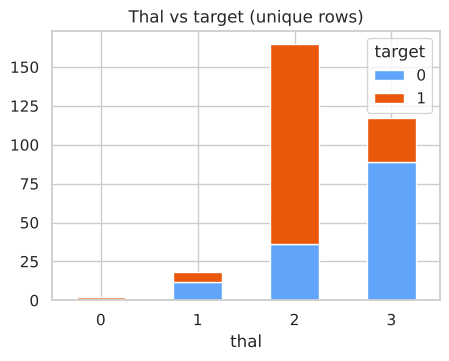

In [19]:
# M8 thalassemia (thal) distribution against target
for nm,d in (('All rows',raw),('Unique rows',data)):
    ct=pd.crosstab(d.thal,d.target); print(nm); display(ct); print('share with target = 1:',(ct[1]/ct.sum(1)).round(3).to_dict())
pd.crosstab(data.thal,data.target).plot(kind='bar',stacked=True,figsize=(5,3.5),color=['#60a5fa','#ea580c']); plt.title('Thal vs target (unique rows)'); plt.xticks(rotation=0); plt.show()

In [20]:
# M9 most common risk-factor combinations among target = 1 patients
for nm,d in (('All rows',raw),('Unique rows',data)):
    c=d[d.target==1].groupby(['cp','fbs','exang','thal']).size().reset_index(name='patients').sort_values('patients',ascending=False).head(5)
    c['share_of_target1_%']=(c.patients/(d.target==1).sum()*100).round(1); print(nm); display(c)

All rows


,cp,fbs,exang,thal,patients,share_of_target1_%
15,2,0,0,2,133,25.3
8,1,0,0,2,97,18.4
1,0,0,0,2,73,13.9
19,2,1,0,2,32,6.1
16,2,0,0,3,19,3.6


Unique rows


,cp,fbs,exang,thal,patients,share_of_target1_%
15,2,0,0,2,41,25.0
8,1,0,0,2,30,18.3
1,0,0,0,2,23,14.0
19,2,1,0,2,10,6.1
4,0,0,1,2,6,3.7


All rows


,Measure,Mean t=0,Mean t=1,Median t=0,Median t=1,Cohen d,p-value
0,age,56.57,52.41,58.0,52.0,-0.47,0.0000
1,trestbps,134.11,129.25,130.0,130.0,-0.28,0.0000
2,chol,251.29,240.98,249.0,234.0,-0.20,0.0013
3,thalach,139.13,158.59,142.0,161.5,0.93,0.0000
4,oldpeak,1.60,0.57,1.4,0.2,-0.97,0.0000


Unique rows


,Measure,Mean t=0,Mean t=1,Median t=0,Median t=1,Cohen d,p-value
0,age,56.60,52.59,58.0,52.0,-0.46,0.0001
1,trestbps,134.40,129.25,130.0,130.0,-0.29,0.0120
2,chol,251.09,242.64,249.0,234.5,-0.16,0.1553
3,thalach,139.10,158.38,142.0,161.0,0.92,0.0000
4,oldpeak,1.59,0.59,1.4,0.2,-0.93,0.0000


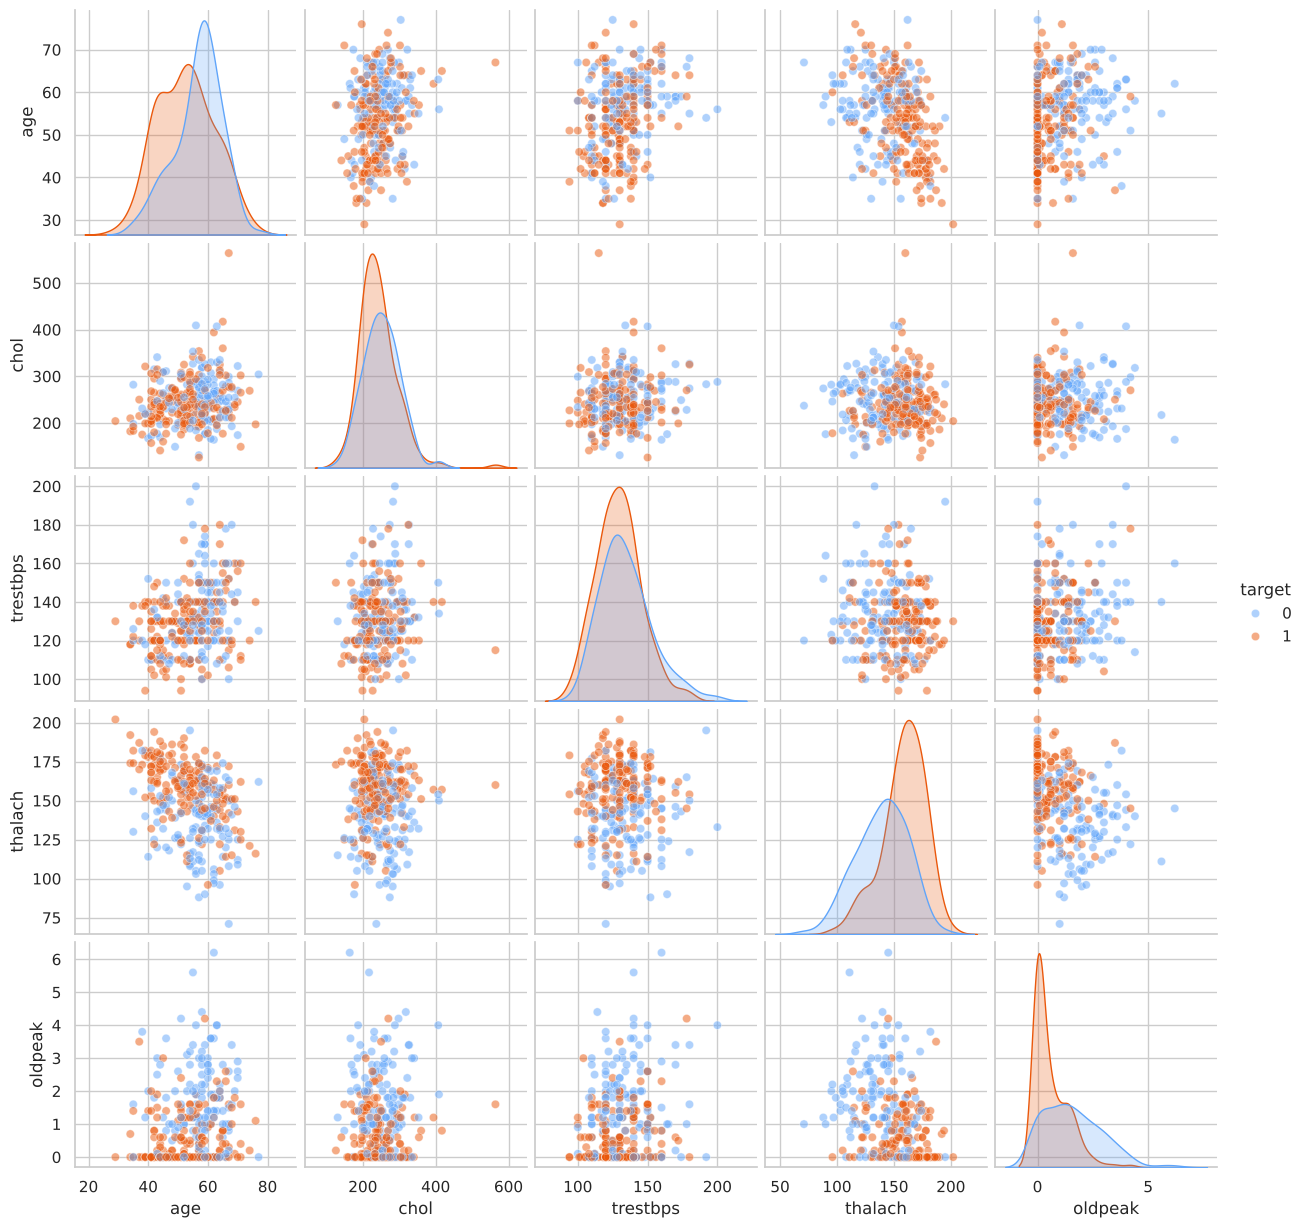

In [21]:
# M10 comparison of clinical measurements, target = 1 vs target = 0
for nm,d in (('All rows',raw),('Unique rows',data)):
    out=[]
    for c in num:
        a,b=d[d.target==1][c],d[d.target==0][c]; t=stats.ttest_ind(a,b,equal_var=False)
        out.append([c,round(b.mean(),2),round(a.mean(),2),round(b.median(),2),round(a.median(),2),round((a.mean()-b.mean())/np.sqrt((a.var()+b.var())/2),2),round(t.pvalue,4)])
    print(nm); display(pd.DataFrame(out,columns=['Measure','Mean t=0','Mean t=1','Median t=0','Median t=1','Cohen d','p-value']))
sns.pairplot(data,hue='target',vars=['age','chol','trestbps','thalach','oldpeak'],palette=['#60a5fa','#ea580c'],plot_kws={'alpha':.5}); plt.show()

## 5. Advanced questions

In [22]:
# A1 combined effect of age, cholesterol and blood pressure
for nm,d in (('All rows',raw),('Unique rows',data)):
    r=d.copy(); r['n_flags']=(r.age>=55).astype(int)+(r.chol>=240).astype(int)+(r.trestbps>=140).astype(int)
    print(nm,'- share with target = 1 by number of flags (age>=55, chol>=240, BP>=140):'); display(r.groupby('n_flags').target.agg(['count','mean']).round(3))
    X=sm.add_constant(d[['age','chol','trestbps']]); lm=sm.Logit(d.target,X).fit(disp=0)
    print('odds ratios:',np.exp(lm.params).round(3).drop('const').to_dict(),'| p-values:',lm.pvalues.round(4).drop('const').to_dict(),'| AUC:',round(roc_auc_score(d.target,lm.predict(X)),3))

All rows - share with target = 1 by number of flags (age>=55, chol>=240, BP>=140):


,count,mean
n_flags,,
0,227,0.714
1,340,0.571
2,324,0.380
3,134,0.351


odds ratios: {'age': 0.955, 'chol': 0.998, 'trestbps': 0.991} | p-values: {'age': 0.0, 'chol': 0.1354, 'trestbps': 0.0143} | AUC: 0.651
Unique rows - share with target = 1 by number of flags (age>=55, chol>=240, BP>=140):


,count,mean
n_flags,,
0,65,0.738
1,103,0.602
2,94,0.415
3,40,0.375


odds ratios: {'age': 0.957, 'chol': 0.999, 'trestbps': 0.99} | p-values: {'age': 0.0019, 'chol': 0.5836, 'trestbps': 0.1383} | AUC: 0.647


,All rows,Unique rows
exang,-0.438,-0.436
cp,0.435,0.432
oldpeak,-0.438,-0.429
thalach,0.423,0.420
ca,-0.382,-0.409
slope,0.346,0.344
thal,-0.338,-0.343
sex,-0.280,-0.284
age,-0.229,-0.221
trestbps,-0.139,-0.146


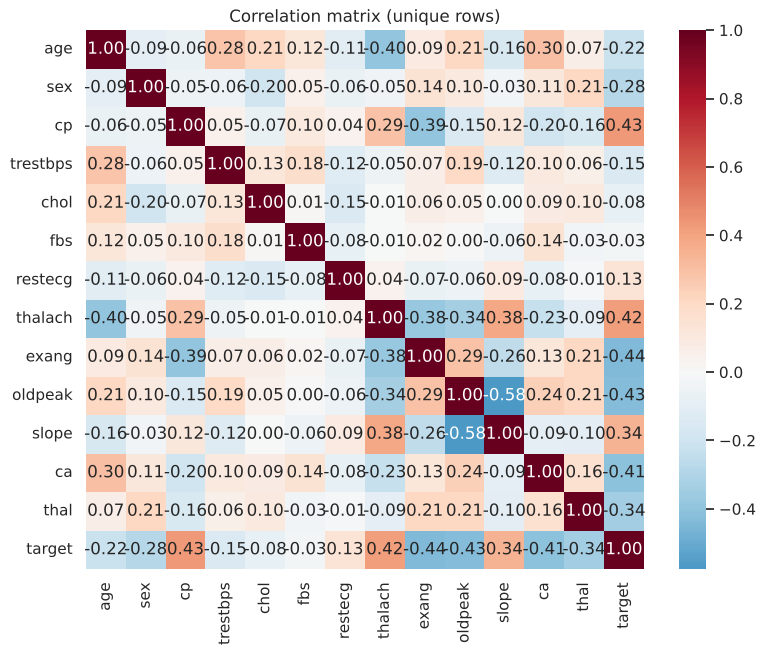

In [23]:
# A2 strongest correlation with target
cor=pd.DataFrame({'All rows':raw.corr()['target'],'Unique rows':data.corr()['target']}).drop('target').round(3)
cor=cor.reindex(cor['Unique rows'].abs().sort_values(ascending=False).index); display(cor)
plt.figure(figsize=(9,7)); sns.heatmap(data.corr(),annot=True,fmt='.2f',cmap='RdBu_r',center=0); plt.title('Correlation matrix (unique rows)'); plt.show()

All rows (duplicates can leak between folds) | 5-fold CV AUC: 0.92 | CV accuracy: 0.846
Unique rows | 5-fold CV AUC: 0.905 | CV accuracy: 0.831
Hold-out (unique rows, 25%): accuracy 0.803 | AUC 0.875
[[25 10]
 [ 5 36]]


,standardised coef,odds ratio per 1 SD
cp,0.831,2.295
ca,-0.790,0.454
sex,-0.767,0.465
oldpeak,-0.582,0.559
thal,-0.524,0.592
thalach,0.502,1.653
exang,-0.451,0.637
slope,0.348,1.417
trestbps,-0.331,0.718
restecg,0.225,1.252


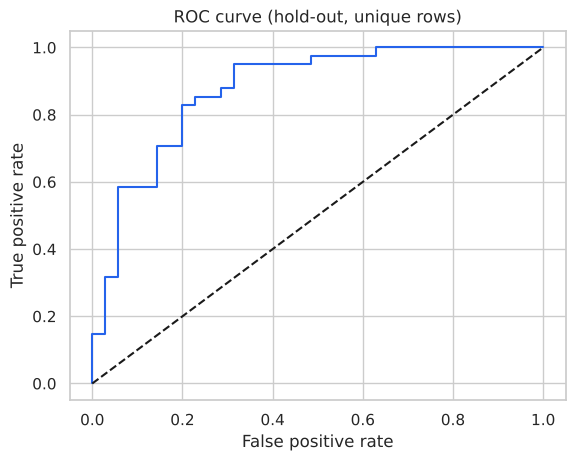

In [24]:
# A3 logistic regression with all features
feats=[c for c in data.columns if c!='target']
pipe=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)); cv=StratifiedKFold(5,shuffle=True,random_state=42)
for nm,d in (('All rows (duplicates can leak between folds)',raw),('Unique rows',data)):
    X,y=d[feats],d.target
    print(nm,'| 5-fold CV AUC:',round(cross_val_score(pipe,X,y,cv=cv,scoring='roc_auc').mean(),3),'| CV accuracy:',round(cross_val_score(pipe,X,y,cv=cv,scoring='accuracy').mean(),3))
X,y=data[feats],data.target; Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=42,stratify=y)
pipe.fit(Xtr,ytr); pr=pipe.predict(Xte); pp=pipe.predict_proba(Xte)[:,1]
print('Hold-out (unique rows, 25%): accuracy',round(accuracy_score(yte,pr),3),'| AUC',round(roc_auc_score(yte,pp),3)); print(confusion_matrix(yte,pr))
pipe.fit(X,y); coef=pd.DataFrame({'standardised coef':pipe[-1].coef_[0],'odds ratio per 1 SD':np.exp(pipe[-1].coef_[0])},index=feats).round(3)
display(coef.reindex(coef['standardised coef'].abs().sort_values(ascending=False).index))
fp,tp,_=roc_curve(yte,pp); plt.plot(fp,tp,color='#2563eb'); plt.plot([0,1],[0,1],'k--'); plt.title('ROC curve (hold-out, unique rows)'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.show()

All rows


slope,0,1,2
cp,,,
0,42,292,163
1,8,41,118
2,15,110,159
3,9,39,29


slope,0,1,2
cp,,,
0,8.5,58.8,32.8
1,4.8,24.6,70.7
2,5.3,38.7,56.0
3,11.7,50.6,37.7


Unique rows


slope,0,1,2
cp,,,
0,11,84,48
1,2,12,36
2,5,33,48
3,3,11,9


slope,0,1,2
cp,,,
0,7.7,58.7,33.6
1,4.0,24.0,72.0
2,5.8,38.4,55.8
3,13.0,47.8,39.1


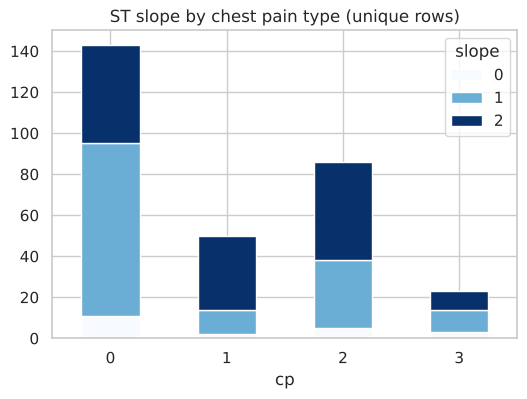

In [25]:
# A4 slope of peak exercise ST segment by chest pain type
for nm,d in (('All rows',raw),('Unique rows',data)):
    print(nm); display(pd.crosstab(d.cp,d.slope)); display((pd.crosstab(d.cp,d.slope,normalize='index')*100).round(1))
pd.crosstab(data.cp,data.slope).plot(kind='bar',stacked=True,figsize=(6,4),colormap='Blues'); plt.title('ST slope by chest pain type (unique rows)'); plt.xticks(rotation=0); plt.show()

**A5. Survival rates by thalassemia type: not possible.** The dataset is a single snapshot (one row per patient) with no follow-up time, outcome date or death indicator, so survival cannot be computed. The hint's `lineplot(age, thal, hue=target)` does not show survival. The closest valid analysis is the share of `target = 1` by thal type and age group, shown below as a descriptive substitute only.

In [26]:
ab=pd.cut(data.age,[0,44,54,64,100],labels=['<45','45-54','55-64','65+'])
display((pd.crosstab(ab,data.thal,values=data.target,aggfunc='mean')*100).round(0))
display(pd.crosstab(ab,data.thal))

thal,0,1,2,3
age,,,,
<45,NaN,33.0,95.0,29.0
45-54,50.0,100.0,87.0,29.0
55-64,NaN,27.0,59.0,21.0
65+,NaN,33.0,71.0,21.0


thal,0,1,2,3
age,,,,
<45,0,3,38,14
45-54,2,1,54,31
55-64,0,11,49,58
65+,0,3,24,14


## 6. Insights and recommendations
- **Strongest associations with `target`:** exercise angina, chest pain type, ST depression (oldpeak), maximum heart rate and number of major vessels (all about 0.4 in absolute correlation). Cholesterol, fasting sugar and resting ECG are weak.
- **Model:** logistic regression with all 13 features reaches a cross-validated AUC of about 0.90 on unique rows (accuracy about 83%). Chest pain type, sex, maximum heart rate, major vessels and thal are the largest contributors.
- **Duplicates matter:** more than two thirds of the rows are repeats, which inflates counts and leaks between cross-validation folds. Use the unique rows for models and tests.
- **Label direction must be verified** (section 2) before any clinical or preventive recommendation is drawn from the direction of an effect.
- **Preventive focus (conditional on the label check):** screen patients with exercise angina, abnormal ST depression and multiple affected vessels first; monitor blood pressure and cholesterol, which are common but weak discriminators here.
- **Limitations:** no survival or follow-up data; one hospital snapshot; age 29 to 77 only; associations, not causes.